# Cartesian Sampling Image Characteristics

**Part:** G – Image characteristics · **Reading time:** ~45 min · **Pass 1 overview:** [Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

**Why this chapter matters.** The most common type of pulse sequence samples k-space on a Cartesian grid using frequency and phase encoding. This chapter is the "engineering datasheet" of such a sequence: it collects, in one place, the formulas that connect the knobs on the scanner console (FOV, matrix, slice thickness, bandwidth, TR, NEX) to what you get (resolution, scan time, SNR) and to what the hardware must deliver (gradient amplitudes and durations). At the end you get a small Python **protocol calculator** that does all of this for you, with worked examples.

## Learning goals

1. Describe how images are formed
    * Determine the image FOV and resolution when using Cartesian sampling
    * Determine the scan time when using Cartesian sampling
1. Manipulate MRI sequence parameters to improve performance
    * Determine how Cartesian sequence parameters will change FOV and resolution
    * Determine how changes in sequence parameters will affect the scan time and SNR
    * Check whether a protocol is feasible on given gradient hardware, and estimate the minimum TE

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio | Hz/T | 42.58 MHz/T (¹H) |
| $\vec k=[k_x,k_y,k_z]$ | k-space position, $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$ | m⁻¹ (cycles/m) | |
| $\Delta k_x,\Delta k_y$ | k-space sample spacing in x / y | m⁻¹ | ~4 m⁻¹ |
| $k_{x,max}, k_{y,max}$ | largest k sampled in x / y | m⁻¹ | ~500 m⁻¹ |
| $FOV_x, FOV_y$ | field of view in readout / phase-encode direction | m | 0.2–0.5 m |
| $\delta_x,\delta_y,\delta_z$ | spatial resolution (voxel size) in x, y, z | m | 0.5–5 mm |
| $\Delta z$ | slice thickness ($=\delta_z$ in 2D) | m | 1–10 mm |
| $N_{read}$ | number of readout samples (original: $N_{FE}$) | – | 128–512 |
| $N_{PE}$ | number of phase-encoding steps | – | 128–512 |
| $G_{x,r}$ | readout gradient amplitude (original figure: $G_{xr}$) | T/m | 2–30 mT/m |
| $G_{y,PE}$ | largest phase-encoding gradient amplitude (figure: $G_{yp}$) | T/m | 5–30 mT/m |
| $G_{yi}$ | phase-encoding amplitude increment between steps | T/m | ~0.1 mT/m |
| $t_y$ | duration of the phase-encoding gradient lobe | s | 0.5–2 ms |
| $G_{z,SS}$ | slice-select gradient amplitude | T/m | 5–30 mT/m |
| $T_{rf}$ | RF pulse duration | s | 1–4 ms |
| $TBW$ | time–bandwidth product of the RF pulse | – | 2–8 |
| $BW_{rf}=TBW/T_{rf}$ | RF pulse bandwidth | Hz | 1–4 kHz |
| $\Delta t$ | dwell time = ADC sampling interval (figure: $\Delta T_s$) | s | 2–20 µs |
| $BW_{read}=1/\Delta t$ | total receiver bandwidth (figure: $RBW$) | Hz | 32–500 kHz |
| $BW_{pix}=BW_{read}/N_{read}$ | bandwidth per pixel | Hz | 100–1000 Hz |
| $T_{read}=N_{read}\Delta t$ | readout duration | s | 2–10 ms |
| $TE$, $TR$ | echo time, repetition time | s | |
| $\theta$ | flip angle | rad | |
| $NEX$ | number of averages (original: $N_{avg}$) | – | 1–4 |
| $N_{TR}$ | number of TRs in the scan | – | |
| $N_{slices}$ | number of slices in a 2D multi-slice scan | – | 1–60 |
| $T_{scan}$ | total scan time | s | |
| $T_{meas}$ | total ADC sampling time | s | |
| $SNR$, $f_{seq}$ | signal-to-noise ratio; sequence factor (transverse magnetization at TE relative to $M_0$) | – | |
| $\Delta V$ | voxel volume $\delta_x\delta_y\delta_z$ | m³ | |
| $G_{max}$, $SR$ | maximum gradient amplitude; maximum slew rate | T/m, T/m/s | 40 mT/m, 150 T/m/s |
| $B_0$ | main field | T | 1.5, 3 T |
| $\Delta f_{cs}$ | fat–water chemical-shift frequency | Hz | ≈ −440 Hz at 3 T |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## Cartesian pulse sequence

The following pulse sequence diagram shows a Cartesian 2D FT sequence including the pulse amplitudes and durations needed to determine the image characteristics. A gradient-echo sequence is shown; the principles extend directly to a spin-echo sequence (see [Gradient and Spin Echoes](D3_Gradient_and_Spin_Echoes.ipynb)). Idealized rectangular gradients are shown for simplicity; real gradients are trapezoids with ramps limited by the slew rate (see [Gradient System Engineering](B4_Gradient_System_Engineering.ipynb)).

![Cartesian 2D FT gradient-echo pulse sequence with parameters](../images/pulse_sequence-diagram-Cartesian-parameters.png)

*Notation mapping between the figure and this notebook:* $G_{xr}\to G_{x,r}$ (readout amplitude), $G_{yp}\to G_{y,PE}$ (largest phase-encode amplitude; the dotted levels in between are the $N_{PE}$ steps spaced by $G_{yi}$), $\Delta T_s=1/RBW\to\Delta t=1/BW_{read}$. The phase-encoding lobe lasts $t_y$ (the width of the $G_Y$ blocks), and the whole bracket is repeated $N_{TR}$ times. The negative $G_X$ lobe before the readout is the **prephaser** (moves k to $-k_{x,max}$), the negative $G_Z$ lobe is the **slice refocusing** lobe, and the lobes after the readout are **rewinders/spoilers** ([K-space](F2_K-space.ipynb)).

## Spatial resolution

The spatial resolution is determined by the maximum sample extent in k-space, $\delta = 1/(2k_{max})$ (derived from the Fourier "finite window ↔ sinc blur" pair in [FOV and Resolution](G1_FOV_and_Resolution.ipynb)).

### Frequency-encoding (readout) direction

During the readout, $G_{x,r}$ is constant, so the k-space position moves at constant speed: $k_x(t)=\bar\gamma G_{x,r}(t-TE)$, running from $-k_{x,max}$ to $+k_{x,max}$ (the prephaser put it at $-k_{x,max}$). Over the whole readout duration $T_{read}$ it covers a width $W_{k_x}=2k_{x,max}=\bar\gamma G_{x,r}T_{read}$, i.e. the **total gradient area during the readout** times $\bar\gamma$. Hence

$$ \delta_x = \frac{1}{2k_{x,max}} = \frac{1}{\bar \gamma\, G_{x,r}\, T_{read}}$$

**In words:** a stronger readout gradient or a longer readout sweeps farther out in k-space and gives smaller pixels.

where $\bar\gamma$ [Hz/T] = gyromagnetic ratio, $G_{x,r}$ [T/m] = readout gradient amplitude, $T_{read}$ [s] = readout duration. Units: $1/(\text{Hz T}^{-1}\cdot\text{T m}^{-1}\cdot\text{s}) = \text{m}$ ✓. Example: $G_{x,r}=6.26$ mT/m, $T_{read}=4$ ms → $\delta_x=1/(42.58\times10^6\cdot6.26\times10^{-3}\cdot4\times10^{-3})=0.94$ mm.

### Phase-encoding direction

In the phase encoding we calculate the maximum k-space extent from the largest phase-encoding gradient area:

$$k_{y,max} = \bar \gamma\, G_{y,PE}\, t_{y}$$

$$ \delta_y = \frac{1}{2 k_{y,max}} = \frac{1}{ 2\,\bar \gamma\, G_{y,PE}\, t_{y}}$$

**In words:** the strongest phase-encoding step decides how fine the y-resolution is; its area (amplitude × duration) is what counts.

where $G_{y,PE}$ [T/m] = largest phase-encoding amplitude, $t_y$ [s] = duration of the phase-encoding lobe.

### Slice-select direction

In the slice-select direction (2D imaging), the spatial resolution is the slice thickness, set by the RF pulse bandwidth and the slice-select gradient ([Slice Selection](E2_Slice_Selection.ipynb)):

$$ \delta_z = \Delta z = \frac{BW_{rf}}{\bar{\gamma}\, G_{z,SS}} = \frac{TBW / T_{rf}}{\bar{\gamma}\, G_{z,SS}}$$

**In words:** the slice contains the positions whose resonance frequency (shifted by the slice gradient) falls inside the pulse's frequency band.

where $BW_{rf}$ [Hz] = RF bandwidth, $TBW$ [–] = time–bandwidth product, $T_{rf}$ [s] = pulse duration, $G_{z,SS}$ [T/m] = slice-select amplitude. Example: $TBW=4$, $T_{rf}=2$ ms → $BW_{rf}=2$ kHz; for $\Delta z=3$ mm we need $G_{z,SS}=2000/(42.58\times10^6\cdot0.003)=15.7$ mT/m.

> **⚠️ Common confusion:** $\delta_z$ in 2D is *not* a Fourier resolution: the slice profile is the (approximately rect-shaped) excitation profile, while $\delta_x,\delta_y$ are sinc-shaped point spread functions (see [Point Spread Function Analysis](I1_Point_Spread_Function_Analysis.ipynb)). In 3D imaging, z is phase encoded as well and $\delta_z=1/(2k_{z,max})$ ([Volumetric Imaging](H1_Volumetric_Imaging.ipynb)).

## Field of view (FOV)

The FOV is determined by the sample spacing in k-space, $FOV=1/\Delta k$ (Fourier "sampling ↔ replication" pair, see [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) and [FOV and Resolution](G1_FOV_and_Resolution.ipynb)).

### Readout direction

In the frequency encoding, consecutive ADC samples are $\Delta t$ apart, during which k moves by $\Delta k_x=\bar\gamma G_{x,r}\Delta t$. With $\Delta t = 1/BW_{read}$:

$$ FOV_x = \frac{1}{\Delta k_x} = \frac{1}{\bar \gamma\, G_{x,r}\, \Delta t} = \frac{BW_{read}}{\bar\gamma\, G_{x,r}}$$

**In words:** the receiver bandwidth is the range of frequencies we can record; the gradient converts frequency into position; the FOV is the range of positions whose frequencies fit into the bandwidth.

where $\Delta t$ [s] = dwell time, $BW_{read}$ [Hz] = total receiver bandwidth. Example: $BW_{read}=64$ kHz, $FOV_x=0.24$ m → $G_{x,r}=64\,000/(42.58\times10^6\cdot0.24)=6.26$ mT/m.

### Phase-encoding direction

In the phase encoding, the spacing is determined by the difference in gradient area between adjacent phase-encoding steps, $\Delta k_y=\bar\gamma G_{yi}t_y$:

$$ FOV_y = \frac{1}{\Delta k_y} = \frac{1}{\bar \gamma\, G_{yi}\, t_y}$$

**In words:** the smaller the step in phase-encoding area from one TR to the next, the larger the FOV in y.

where $G_{yi}$ [T/m] = amplitude increment, $t_y$ [s] = lobe duration.

> **Correction to the original:** the original writes $FOV_y=1/(\bar\gamma G_{yi}\Delta t_y)$. The time here is the phase-encoding lobe *duration* $t_y$ (the area step is $G_{yi}\cdot t_y$), not a time increment – the duration is the same for all steps; only the amplitude changes.

### Matrix size relations

All these relationships can also be rewritten using the relationship between FOV, resolution and number of samples:

$$ FOV_x = N_{read}\ \delta_x, \qquad FOV_y = N_{PE}\ \delta_y$$

**In words:** the image is $N$ pixels of size $\delta$ wide.

where $N_{read}$ = number of samples in the frequency-encoding direction (original: $N_{FE}$) and $N_{PE}$ = number of phase-encoding steps. You can check consistency: $FOV_x/\delta_x = \bar\gamma G_{x,r}T_{read}/(\bar\gamma G_{x,r}\Delta t)=T_{read}/\Delta t = N_{read}$ ✓.

> **⚠️ Common confusion – $N$ or $N-1$?** The original's phase-encoding formula $G_y^{(n)}=-G_{y,PE}+(n-1)G_{yi}$, $n=1..N_{PE}$, is symmetric, so $2G_{y,PE}=(N_{PE}-1)G_{yi}$ and $\delta_y=1/(2k_{y,max})=FOV_y/(N_{PE}-1)$, not exactly $FOV_y/N_{PE}$. The discrepancy comes from defining $\delta$ by the outermost *sample* instead of by the width covered by the samples ($N_{PE}\Delta k_y$, each sample "owning" one $\Delta k$). Scanners use $k_y=(n-N_{PE}/2)\Delta k_y$, $n=0..N_{PE}-1$ (so $k_y=0$ is sampled exactly and the grid matches the FFT); then $k_{y,max}=\frac{N_{PE}}{2}\Delta k_y$ in magnitude and $\delta_y=FOV_y/N_{PE}$ exactly. For $N=256$ the difference is 0.4% – irrelevant in practice, but it explains why textbooks differ.

## Scan time

For this sequence, the total scan time is determined by the TR and the number of TRs, $N_{TR}$:

$$T_{scan} = N_{TR} \cdot TR$$

Assuming no acceleration, the number of TRs is the number of phase-encoding steps, $N_{PE}$, times the number of averages, $NEX$:

$$T_{scan} = N_{PE} \cdot NEX \cdot TR$$

**In words:** one TR per phase-encoding line per average. The number of *readout* samples does not appear – all $N_{read}$ samples are collected within one TR, which is why the readout direction is "free" in scan time (and why readout oversampling costs nothing, [FOV and Resolution](G1_FOV_and_Resolution.ipynb)).

where $TR$ [s] = repetition time. Example: $TR=500$ ms, $N_{PE}=256$, $NEX=1$ → 128 s.

**Multi-slice 2D.** Within one TR the scanner usually needs only a short time per slice (RF pulse to end of readout, $T_{slice}\approx TE+T_{read}/2+$ spoiling). The remaining time is used to excite and read *other* slices (interleaving). As long as $N_{slices}\,T_{slice}\le TR$, all slices come at no extra time; otherwise the scan is split into $\lceil N_{slices}T_{slice}/TR\rceil$ "concatenations"/"packages", multiplying the scan time. For **3D** imaging, $T_{scan}=N_{PE,y}\,N_{PE,z}\,NEX\cdot TR$ ([Volumetric Imaging](H1_Volumetric_Imaging.ipynb)).

> **🔧 Engineering reality:** That is why long-TR sequences (T2-weighted spin echo, TR ≈ 4 s) can cover the whole brain in 2D with ~30 slices "free", whereas short-TR gradient echoes (TR ≈ 10 ms) fit only one slice per TR and are therefore usually acquired in 3D.

## SNR

The original leaves "SNR written with these parameters" as an exercise. Here it is. Start from the general SNR equation ([Signal to Noise Ratio](G2_Signal_to_Noise_Ratio.ipynb)):

$$SNR\propto f_{seq}\cdot\delta_x\delta_y\delta_z\cdot\sqrt{T_{meas}}$$

and insert the Cartesian relations (no acceleration):

* $\delta_x=FOV_x/N_{read}$, $\delta_y=FOV_y/N_{PE}$, $\delta_z=\Delta z$,
* $T_{meas}=N_{TR}\,T_{read}=N_{PE}\cdot NEX\cdot N_{read}\,\Delta t=N_{PE}\cdot NEX\cdot N_{read}/BW_{read}$.

Then

$$SNR\propto f_{seq}\,\frac{FOV_x\,FOV_y\,\Delta z}{N_{read}\,N_{PE}}\sqrt{\frac{N_{PE}\,NEX\,N_{read}}{BW_{read}}} = f_{seq}\,\frac{FOV_x\,FOV_y\,\Delta z\,\sqrt{NEX}}{\sqrt{N_{read}\,N_{PE}\,BW_{read}}}$$

**In words:** SNR grows with the FOVs and slice thickness (bigger voxels), with $\sqrt{NEX}$, and falls with the square root of the matrix sizes and of the bandwidth.

Two equivalent forms that are often more practical:

$$SNR\propto f_{seq}\,\frac{FOV_x\,FOV_y\,\Delta z\,\sqrt{NEX}}{N_{read}\sqrt{N_{PE}\,BW_{pix}}}\qquad\text{(with } BW_{pix}=BW_{read}/N_{read}\text{)}$$

$$SNR\propto f_{seq}\;\delta_x\,\delta_y\,\Delta z\;\sqrt{\frac{N_{PE}\cdot NEX}{BW_{pix}}}$$

**In words:** the first form shows that increasing $N_{read}$ at constant bandwidth *per pixel* costs a full factor $N_{read}$ in SNR (the voxels shrink, but the readout duration $T_{read}=1/BW_{pix}$ stays the same, so no measurement time is gained); the second form shows that, at fixed voxel size, more phase-encode lines and a lower bandwidth per pixel help.

where every symbol is defined in the table above. The sequence factor $f_{seq}$ depends on TR, TE, $\theta$ and the tissue (e.g. spoiled GRE: $f_{seq}=M_0\sin\theta\frac{1-E_1}{1-\cos\theta E_1}e^{-TE/T_2^*}$, $E_1=e^{-TR/T_1}$). The proportionality constant contains $B_0$ (roughly $\propto B_0$) and the coil.

<details><summary><b>📐 Derivation check (optional): the readout direction</b></summary>

Doubling $N_{read}$ at fixed $FOV_x$ and fixed $BW_{read}$: $\delta_x$ halves (×½), $T_{read}=N_{read}/BW_{read}$ doubles (×$\sqrt2$ in SNR) → net $1/\sqrt2$. In the formula: $1/\sqrt{N_{read}}$ ✓.

Doubling $N_{read}$ at fixed $FOV_x$ and fixed $BW_{pix}$ (i.e. $BW_{read}$ doubles too): $\delta_x$ ×½, $T_{read}=1/BW_{pix}$ unchanged → net ½. In the formula: $1/\sqrt{N_{read}\cdot BW_{read}}=1/\sqrt{2\cdot2}$ ✓.

</details>

## Parameter trade-off table

Change one parameter, keep all others fixed (2D Cartesian, no acceleration):

| Change | $\delta_x$, $\delta_y$, $\delta_z$ | FOV | $T_{scan}$ | SNR | Other effects |
|---|---|---|---|---|---|
| $FOV_x$ and $FOV_y$ ×2 (same matrix) | ×2, ×2, – | ×2 | – | ×4 | coarser detail; lower $G_{x,r}$ and $G_{yi}$ needed |
| $FOV_y$ ×½ only (same matrix) | –, ×½, – | ×½ in y | – | ×½ | aliasing (wrap-around) if the object is larger than $FOV_y$ |
| $N_{PE}$ ×2 (same FOV) | –, ×½, – | – | ×2 | ×$1/\sqrt2$ | |
| $N_{PE}$ ×2 and $FOV_y$ ×2 | –, –, – | ×2 in y | ×2 | ×$\sqrt2$ | covers larger anatomy, same pixel ("phase oversampling") |
| $N_{read}$ ×2 (same FOV, same $BW_{read}$) | ×½, –, – | – | – | ×$1/\sqrt2$ | $T_{read}$ ×2 → longer min. TE/TR; same $G_{x,r}$ |
| $N_{read}$ ×2 (same FOV, same $BW_{pix}$) | ×½, –, – | – | – | ×½ | $G_{x,r}$ ×2 |
| $BW_{read}$ ×½ | – | – | – (if TR allows) | ×$\sqrt2$ | $T_{read}$ ×2, chemical shift & distortion ×2 (pixels), $G_{x,r}$ ×½, more $T_2^*$ blur |
| $NEX$ ×2 | – | – | ×2 | ×$\sqrt2$ | averages out some motion ghosts |
| $\Delta z$ ×2 | –, –, ×2 | – | – | ×2 | partial-volume effects; fewer slices for same coverage; $G_{z,SS}$ ×½ |
| $TR$ ×2 | – | – | ×2 | depends on $f_{seq}$ (↑ for $T_1$ recovery) | contrast changes ($T_1$ weighting ↓); more slices per TR |
| $B_0$ 1.5 → 3 T | – | – | – | ≈×2 (body-noise regime; less in practice) | $T_1$ longer, chemical shift (Hz) ×2, SAR ×4, $B_1^+$ inhomogeneity |

The protocol calculator below reproduces every row of this table.

## A Python protocol calculator

The function below turns a protocol (what you type on the console) into everything we derived: resolution, k-space numbers, ADC timing, required gradients (checked against the hardware limits $G_{max}$ and $SR$), an estimate of the minimum TE, scan time and SNR relative to a reference protocol.

The minimum-TE estimate assumes trapezoidal gradients with ramp time $G/SR$, the slice-refocusing, readout-prephasing and phase-encoding lobes played *simultaneously*, and an echo in the middle of the readout:

$$TE_{min}\approx \tfrac{T_{rf}}{2} + t_{ramp,SS} + \max\big(t_{refocus},\,t_{prephase},\,t_{PE}\big) + t_{ramp,read} + \tfrac{T_{read}}{2}$$

**In words:** half the RF pulse, plus the time to bring k from the slice-select end to the readout start, plus half the readout.

where each lobe duration is the shortest trapezoid (or triangle) of the required area within $G_{max}$ and $SR$. It is a rough, gradient-echo estimate (real sequences add a few hundred µs for e.g. ADC setup; spin echoes need room for the 180° pulse).

In [2]:
GB = mt.GAMMA_BAR   # [Hz/T]

def lobe_duration(area, G_max, SR):
    """Shortest trapezoid/triangle with gradient area `area` [T s/m] under G_max [T/m], slew SR [T/m/s].
    Returns total duration [s] (including ramps)."""
    area = abs(area)
    t_ramp = G_max / SR
    if area <= G_max * t_ramp:                 # triangle never reaches G_max
        return 2 * np.sqrt(area / SR)
    return area / G_max + t_ramp               # trapezoid: flat = area/G_max - t_ramp, plus two ramps

def protocol(FOV_x=0.24, FOV_y=0.24, N_read=256, N_PE=256, dz=3e-3, BW_read=64e3,
             TR=0.5, TE=10e-3, NEX=1, B0=3.0, N_slices=1,
             G_max=40e-3, SR=150.0, T_rf=2e-3, TBW=4.0, f_seq=1.0):
    """Compute image characteristics of a 2D Cartesian gradient-echo protocol (all inputs SI)."""
    p = dict(locals())
    # --- resolution & k-space (scanner convention k = (n - N/2) * dk) ---
    p["dx"], p["dy"] = FOV_x / N_read, FOV_y / N_PE
    p["dk_x"], p["dk_y"] = 1 / FOV_x, 1 / FOV_y
    p["kx_max"], p["ky_max"] = N_read / 2 * p["dk_x"], N_PE / 2 * p["dk_y"]   # = 1/(2 delta)
    # --- readout ---
    p["dt"] = 1 / BW_read
    p["T_read"] = N_read * p["dt"]
    p["BW_pix"] = BW_read / N_read
    p["G_xr"] = BW_read / (GB * FOV_x)                     # FOV_x = BW_read / (gamma_bar G_xr)
    p["fat_shift_px"] = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)) / p["BW_pix"]
    # --- slice selection ---
    p["BW_rf"] = TBW / T_rf
    p["G_ss"] = p["BW_rf"] / (GB * dz)
    # --- gradient lobes (areas in T s/m: k = gamma_bar * area) ---
    t_ramp_read = p["G_xr"] / SR
    area_prephase = p["G_xr"] * (p["T_read"] + t_ramp_read) / 2   # half readout area incl. ramp-up
    area_PE = p["ky_max"] / GB                                    # largest PE area  G_y,PE * t_y
    area_refocus = p["G_ss"] * T_rf / 2                           # slice refocusing lobe
    p["t_prephase"] = lobe_duration(area_prephase, G_max, SR)
    p["t_y"] = lobe_duration(area_PE, G_max, SR)
    p["t_refocus"] = lobe_duration(area_refocus, G_max, SR)
    p["TE_min"] = (T_rf / 2 + p["G_ss"] / SR + max(p["t_prephase"], p["t_y"], p["t_refocus"])
                   + t_ramp_read + p["T_read"] / 2)
    # --- timing ---
    p["T_slice"] = max(TE, p["TE_min"]) + p["T_read"] / 2 + 1e-3     # + ~1 ms rewinder/spoiler
    p["N_conc"] = int(np.ceil(N_slices * p["T_slice"] / TR))           # concatenations needed
    p["T_scan"] = TR * N_PE * NEX * p["N_conc"]
    p["T_meas"] = N_PE * NEX * p["T_read"]                             # ADC time per slice
    # --- SNR (arbitrary units): ~ B0 * f_seq * voxel volume * sqrt(T_meas) ---
    p["SNR_au"] = B0 * f_seq * p["dx"] * p["dy"] * dz * np.sqrt(N_PE * NEX * p["T_read"])
    # --- hardware checks ---
    warn = []
    if p["G_xr"] > G_max: warn.append(f"readout gradient {p['G_xr']*1e3:.1f} mT/m > G_max")
    if p["G_ss"] > G_max: warn.append(f"slice-select gradient {p['G_ss']*1e3:.1f} mT/m > G_max")
    if TE < p["TE_min"]:  warn.append(f"TE {TE*1e3:.1f} ms < TE_min {p['TE_min']*1e3:.1f} ms")
    if p["T_slice"] > TR: warn.append("TR too short for even one slice")
    p["warnings"] = warn
    return p

def report(p, ref=None, name=""):
    """Print a protocol summary; SNR and time relative to `ref` if given."""
    rel_snr = p["SNR_au"] / ref["SNR_au"] if ref else 1.0
    rel_t = p["T_scan"] / ref["T_scan"] if ref else 1.0
    print(f"--- {name} ---")
    print(f"  voxel {p['dx']*1e3:.2f} x {p['dy']*1e3:.2f} x {p['dz']*1e3:.1f} mm   FOV {p['FOV_x']*1e3:.0f} x {p['FOV_y']*1e3:.0f} mm"
          f"   matrix {p['N_read']} x {p['N_PE']}")
    print(f"  dk = {p['dk_x']:.2f} 1/m, kx_max = {p['kx_max']:.0f} 1/m, ky_max = {p['ky_max']:.0f} 1/m")
    print(f"  BW_read = {p['BW_read']/1e3:.1f} kHz (+-{p['BW_read']/2e3:.1f}), dt = {p['dt']*1e6:.1f} us, "
          f"BW_pix = {p['BW_pix']:.0f} Hz/px, T_read = {p['T_read']*1e3:.2f} ms, fat shift = {p['fat_shift_px']:.2f} px")
    print(f"  G_x,r = {p['G_xr']*1e3:.2f} mT/m, G_z,SS = {p['G_ss']*1e3:.1f} mT/m, t_y(min) = {p['t_y']*1e3:.2f} ms, "
          f"TE_min ~ {p['TE_min']*1e3:.2f} ms")
    print(f"  T_scan = {p['T_scan']:.1f} s ({p['T_scan']/60:.2f} min)   rel. scan time = {rel_t:.2f}   rel. SNR = {rel_snr:.2f}")
    for w in p["warnings"]:
        print("  WARNING:", w)

ref = protocol()
report(ref, name="reference: 3 T, FOV 240 mm, 256x256, 3 mm, 64 kHz, TR 500 ms, NEX 1")

--- reference: 3 T, FOV 240 mm, 256x256, 3 mm, 64 kHz, TR 500 ms, NEX 1 ---
  voxel 0.94 x 0.94 x 3.0 mm   FOV 240 x 240 mm   matrix 256 x 256
  dk = 4.17 1/m, kx_max = 533 1/m, ky_max = 533 1/m
  BW_read = 64.0 kHz (+-32.0), dt = 15.6 us, BW_pix = 250 Hz/px, T_read = 4.00 ms, fat shift = 1.79 px
  G_x,r = 6.26 mT/m, G_z,SS = 15.7 mT/m, t_y(min) = 0.58 ms, TE_min ~ 3.80 ms
  T_scan = 128.0 s (2.13 min)   rel. scan time = 1.00   rel. SNR = 1.00


The reference protocol reproduces the numbers used throughout this series: $\Delta t=15.6$ µs, $BW_{pix}=250$ Hz/pixel, $T_{read}=4$ ms, $G_{x,r}=6.26$ mT/m, $\delta=0.94$ mm, scan time 128 s. The phase-encoding lobe needs well under a millisecond, and the minimum TE is a few ms.

### Worked examples

Each example changes one thing relative to the reference; compare with the trade-off table.

In [3]:
examples = {
    "1) matrix 512 x 512":                     dict(N_read=512, N_PE=512),
    "2) bandwidth halved (32 kHz)":            dict(BW_read=32e3),
    "3) NEX = 2":                              dict(NEX=2),
    "4) slice 6 mm":                           dict(dz=6e-3),
    "5) same protocol at 1.5 T":               dict(B0=1.5),
    "6) 1.5 T, recover SNR with NEX = 4":      dict(B0=1.5, NEX=4),
    "7) small FOV 100 mm, 250 kHz (too strong?)": dict(FOV_x=0.10, FOV_y=0.10, BW_read=250e3),
    "8) 20 slices, TR = 50 ms, TE = 5 ms":    dict(N_slices=20, TR=50e-3, TE=5e-3),
}
results = {}
for name, change in examples.items():
    results[name] = protocol(**change)
    report(results[name], ref=ref, name=name)

--- 1) matrix 512 x 512 ---
  voxel 0.47 x 0.47 x 3.0 mm   FOV 240 x 240 mm   matrix 512 x 512
  dk = 4.17 1/m, kx_max = 1067 1/m, ky_max = 1067 1/m
  BW_read = 64.0 kHz (+-32.0), dt = 15.6 us, BW_pix = 125 Hz/px, T_read = 8.00 ms, fat shift = 3.58 px
  G_x,r = 6.26 mT/m, G_z,SS = 15.7 mT/m, t_y(min) = 0.89 ms, TE_min ~ 6.04 ms
  T_scan = 256.0 s (4.27 min)   rel. scan time = 2.00   rel. SNR = 0.50
--- 2) bandwidth halved (32 kHz) ---
  voxel 0.94 x 0.94 x 3.0 mm   FOV 240 x 240 mm   matrix 256 x 256
  dk = 4.17 1/m, kx_max = 533 1/m, ky_max = 533 1/m
  BW_read = 32.0 kHz (+-16.0), dt = 31.2 us, BW_pix = 125 Hz/px, T_read = 8.00 ms, fat shift = 3.58 px
  G_x,r = 3.13 mT/m, G_z,SS = 15.7 mT/m, t_y(min) = 0.58 ms, TE_min ~ 5.78 ms
  T_scan = 128.0 s (2.13 min)   rel. scan time = 1.00   rel. SNR = 1.41
--- 3) NEX = 2 ---
  voxel 0.94 x 0.94 x 3.0 mm   FOV 240 x 240 mm   matrix 256 x 256
  dk = 4.17 1/m, kx_max = 533 1/m, ky_max = 533 1/m
  BW_read = 64.0 kHz (+-32.0), dt = 15.6 us, BW_pix

Highlights:
* **(1)** quadrupling the number of pixels halves SNR and doubles time; $T_{read}$ doubles to 8 ms, so $TE_{min}$ grows.
* **(2)** and **(3)** both give √2 more SNR, but (2) is free in scan time (if TE/TR allow) while (3) doubles it; (2) doubles the fat shift to ≈3.5 pixels.
* **(5)/(6)** going from 3 T to 1.5 T halves SNR in this model; recovering it by averaging needs NEX = 4, i.e. 4× the time.
* **(7)** a 100 mm FOV at 250 kHz requires $G_{x,r}=58.7$ mT/m – more than the 40 mT/m available: the calculator flags it. The fix is a lower bandwidth (or a larger FOV).
* **(8)** with TR = 50 ms only 6 slices (of ≈8 ms each) fit into one TR, so the 20 slices are split into 4 concatenations: 51 s instead of $TR\cdot N_{PE}=12.8$ s. (The calculator keeps $f_{seq}=1$; in reality the shorter TR also changes $f_{seq}$ and the contrast – pass `f_seq=mt.spoiled_gre_signal(...)` to include it.)

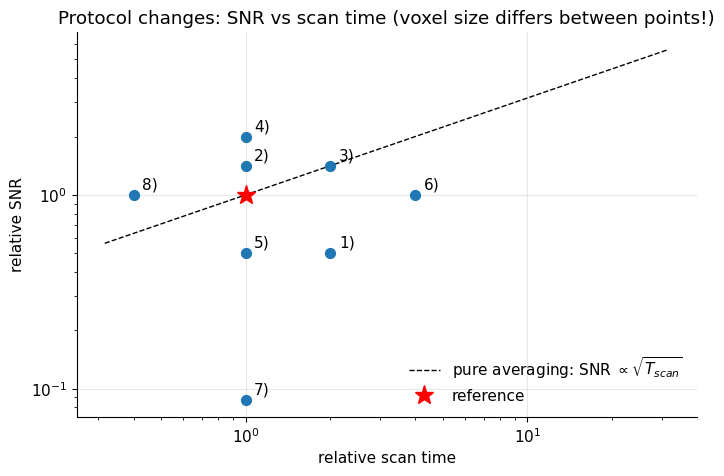

In [4]:
names = list(examples)
rel_snr = [results[n]["SNR_au"] / ref["SNR_au"] for n in names]
rel_t = [results[n]["T_scan"] / ref["T_scan"] for n in names]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(rel_t, rel_snr, s=50, zorder=3)
for n, x, y in zip(names, rel_t, rel_snr):
    ax.annotate(n.split(")")[0] + ")", (x, y), textcoords="offset points", xytext=(6, 4))
tt = np.logspace(-0.5, 1.5, 100)
ax.plot(tt, np.sqrt(tt), "k--", lw=1, label=r"pure averaging: SNR $\propto\sqrt{T_{scan}}$")
ax.plot(1, 1, "r*", ms=14, label="reference")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("relative scan time"); ax.set_ylabel("relative SNR"); ax.legend(loc="lower right")
ax.set_title("Protocol changes: SNR vs scan time (voxel size differs between points!)")
plt.show()

Points on the dashed line trade time for SNR at the "averaging rate"; points above it (e.g. 2, thicker slices 4) gain SNR more cheaply – but always at the cost of something not on this plot (bandwidth artifacts, partial volume). Example 8 is faster than the reference only because its TR is 10× shorter – the concatenations eat much of that gain.

## Seeing the trade-offs: simulated images

To *see* what the calculator predicts, we simulate a few protocols on a high-resolution Shepp–Logan phantom (FOV 240 mm): the k-space of the phantom is computed on a fine $512\times512$ grid, cropped to the protocol's matrix (which sets the resolution, [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb)), and complex Gaussian noise is added with a standard deviation chosen from the calculator's relative SNR (reference: SNR = 15 for the brightest tissue).

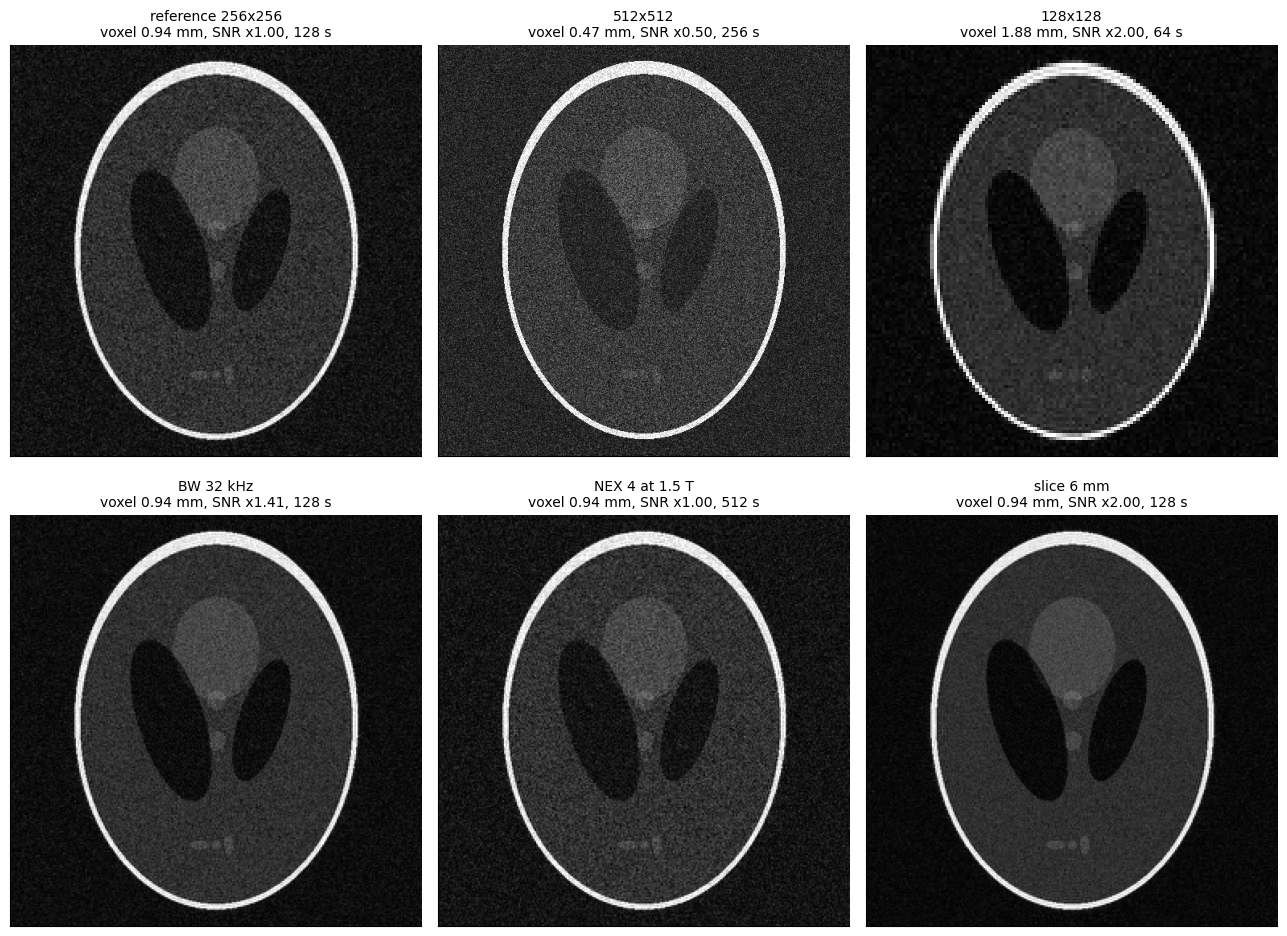

In [5]:
N0 = 512
truth = mt.shepp_logan(N0)                 # fine "continuous" object, values 0..1
K0 = mt.fft2c(truth)                       # its k-space on the fine grid (FOV 240 mm both ways)

def simulate(p, snr_ref=15.0, seed=0):
    """Crop k-space to the protocol matrix (fixed FOV 240 mm assumed) and add noise per predicted SNR."""
    nPE, nRO = p["N_PE"], p["N_read"]
    r0, c0 = N0 // 2 - nPE // 2, N0 // 2 - nRO // 2
    Kc = K0[r0:r0 + nPE, c0:c0 + nRO]
    img = mt.ifft2c(Kc) * np.sqrt(nPE * nRO) / N0          # physical signal level (bright tissue ~1)
    sigma = 1.0 / (snr_ref * p["SNR_au"] / ref["SNR_au"])   # noise std from relative SNR
    return mt.add_complex_noise(img, sigma, rng=np.random.default_rng(seed))

cases = {"reference 256x256": ref,
         "512x512": results["1) matrix 512 x 512"],
         "128x128": protocol(N_read=128, N_PE=128),
         "BW 32 kHz": results["2) bandwidth halved (32 kHz)"],
         "NEX 4 at 1.5 T": results["6) 1.5 T, recover SNR with NEX = 4"],
         "slice 6 mm": results["4) slice 6 mm"]}
fig, ax = plt.subplots(2, 3, figsize=(13, 9.8))
for a, (name, p) in zip(ax.ravel(), cases.items()):
    im = simulate(p)
    mt.show_image(im, ax=a, vmin=0, vmax=1.1)
    a.set_title(f"{name}\nvoxel {p['dx']*1e3:.2f} mm, SNR x{p['SNR_au']/ref['SNR_au']:.2f}, "
                f"{p['T_scan']:.0f} s", fontsize=10)
plt.tight_layout(); plt.show()

The 512 matrix is sharpest but visibly noisier; the 128 matrix is clean but blurred (with Gibbs ringing at edges); halving the bandwidth and thickening the slice reduce noise at no resolution cost in-plane (but with chemical-shift and partial-volume costs not simulated here); NEX = 4 at 1.5 T looks like the 3 T reference but takes 4× as long.

## Try it yourself (interactive)

Change the protocol and watch resolution, scan time and SNR. A static call with the default (reference) parameters comes first.

In [6]:
def explore(N=256, FOV_mm=240, dz_mm=3.0, BW_kHz=64.0, NEX=1, B0=3.0):
    p = protocol(FOV_x=FOV_mm * 1e-3, FOV_y=FOV_mm * 1e-3, N_read=N, N_PE=N, dz=dz_mm * 1e-3,
                 BW_read=BW_kHz * 1e3, NEX=NEX, B0=B0)
    report(p, ref=ref, name="your protocol")

explore()

--- your protocol ---
  voxel 0.94 x 0.94 x 3.0 mm   FOV 240 x 240 mm   matrix 256 x 256
  dk = 4.17 1/m, kx_max = 533 1/m, ky_max = 533 1/m
  BW_read = 64.0 kHz (+-32.0), dt = 15.6 us, BW_pix = 250 Hz/px, T_read = 4.00 ms, fat shift = 1.79 px
  G_x,r = 6.26 mT/m, G_z,SS = 15.7 mT/m, t_y(min) = 0.58 ms, TE_min ~ 3.80 ms
  T_scan = 128.0 s (2.13 min)   rel. scan time = 1.00   rel. SNR = 1.00


In [7]:
try:
    from ipywidgets import interact, Dropdown, FloatSlider, IntSlider
    interact(explore, N=Dropdown(options=[128, 192, 256, 384, 512], value=256),
             FOV_mm=FloatSlider(value=240, min=100, max=450, step=10), dz_mm=FloatSlider(value=3, min=1, max=10, step=0.5),
             BW_kHz=FloatSlider(value=64, min=16, max=500, step=8), NEX=IntSlider(value=1, min=1, max=8),
             B0=Dropdown(options=[0.55, 1.5, 3.0, 7.0], value=3.0))
except ImportError:
    print("ipywidgets not available - call explore(...) directly.")

interactive(children=(Dropdown(description='N', index=2, options=(128, 192, 256, 384, 512), value=256), FloatS…

> **🔧 Engineering reality:** The calculator ignores several real limits: peripheral-nerve-stimulation limits on $dG/dt$ (often below the hardware slew rate, [MRI Safety](B6_MRI_Safety.ipynb)), SAR limits on short-TR / high-flip protocols, gradient duty-cycle and heating limits for long high-amplitude scans ([Gradient System Engineering](B4_Gradient_System_Engineering.ipynb)), and eddy-current delays. Vendor consoles compute all of these in real time and grey out impossible parameter combinations – this is what is happening behind the console when a field turns red.

## Key takeaways

* Resolution comes from k-space extent: $\delta_x=1/(\bar\gamma G_{x,r}T_{read})$, $\delta_y=1/(2\bar\gamma G_{y,PE}t_y)$, $\delta_z=\Delta z=BW_{rf}/(\bar\gamma G_{z,SS})$.
* FOV comes from k-space spacing: $FOV_x=BW_{read}/(\bar\gamma G_{x,r})=1/(\bar\gamma G_{x,r}\Delta t)$, $FOV_y=1/(\bar\gamma G_{yi}t_y)$; and $FOV=N\delta$.
* $T_{scan}=TR\cdot N_{PE}\cdot NEX$ (× concatenations if the slices do not fit into one TR); readout samples are free in time.
* $SNR\propto f_{seq}\,FOV_xFOV_y\Delta z\sqrt{NEX}/\sqrt{N_{read}N_{PE}BW_{read}}$ – equivalently $f_{seq}\,\delta_x\delta_y\Delta z\sqrt{N_{PE}NEX/BW_{pix}}$.
* Every gain has a price: SNR via NEX costs time, via bandwidth costs artifacts and longer TE, via voxel size costs resolution.
* Feasibility is set by the hardware: small FOV + high bandwidth or thin slices with short pulses can exceed $G_{max}$; long readouts lengthen $TE_{min}$.

## Check your understanding

1. At 3 T, you want $FOV_x=200$ mm with $BW_{read}=100$ kHz. What readout gradient is needed? What is the pixel size for $N_{read}=320$, and the readout duration?

<details><summary>Answer</summary>

$G_{x,r}=BW_{read}/(\bar\gamma FOV_x)=10^5/(42.58\times10^6\cdot0.2)=11.7$ mT/m. $\delta_x=200/320=0.625$ mm. $T_{read}=320/10^5=3.2$ ms.

</details>

2. A phase-encoding lobe lasts $t_y=1$ ms. Which increment $G_{yi}$ gives $FOV_y=240$ mm, and which maximum amplitude for $N_{PE}=256$?

<details><summary>Answer</summary>

$G_{yi}=1/(\bar\gamma\,FOV_y\,t_y)=1/(42.58\times10^6\cdot0.24\cdot10^{-3})=0.098$ mT/m. $G_{y,PE}\approx\frac{N_{PE}}{2}G_{yi}=12.5$ mT/m (with the symmetric formula: $\frac{N_{PE}-1}{2}G_{yi}=12.5$ mT/m as well, to three digits).

</details>

3. You change the matrix from $256\times256$ to $256\times192$ ($N_{PE}$ reduced) at the same FOV. Scan time? SNR?

<details><summary>Answer</summary>

Scan time ×0.75. SNR: $\propto 1/\sqrt{N_{PE}}$ at fixed FOV → $\sqrt{256/192}=1.15$, i.e. 15% *more* SNR (larger voxels in y outweigh the shorter measurement), at the price of coarser $\delta_y$ (1.25 mm instead of 0.94 mm).

</details>

4. Why does doubling $N_{read}$ not increase the scan time, while doubling $N_{PE}$ does?

<details><summary>Answer</summary>

All readout samples are acquired in one TR (they only lengthen the readout by $N_{read}\Delta t$, typically a few ms), whereas each phase-encoding step needs its own TR (its own excitation). Hence $T_{scan}=TR\cdot N_{PE}\cdot NEX$.

</details>

5. Which is the cheaper way to gain √2 in SNR: halving $BW_{read}$ or doubling NEX? What do you pay in each case?

<details><summary>Answer</summary>

Halving $BW_{read}$ costs no scan time (if TE/TR permit) but doubles $T_{read}$ (longer $TE_{min}$, more $T_2^*$ decay), doubles the chemical-shift/distortion displacement in pixels. Doubling NEX costs 2× scan time but has no artifact penalty (it even averages out some motion ghosting).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Cartesian Image Characteristics". Changes: every symbol defined with units and examples; derivations of all resolution/FOV formulas; corrected $FOV_y=1/(\bar\gamma G_{yi}t_y)$ (original had $\Delta t_y$), $N$ vs $N-1$ discussion; worked out the SNR "exercise"; added multi-slice timing, trade-off table, a Python protocol calculator with gradient/TE checks, worked examples and image simulations; fixed typos.*